# 00 · Datos y partición

Descarga RoCoLe (Mendeley Data, DOI 10.17632/c5yvn32dzg.2), genera la caché de entrenamiento, explora los datos y verifica la partición por planta.

- **En Colab:** la caché se guarda en `DRIVE_DIR/data` (Google Drive) para no regenerarla en cada sesión.
- **En local:** define `ROCOLE_DATA_ROOT` (por defecto `data/cache`, que está en `.gitignore`).

La partición `data/splits/split.csv` está versionada en el repositorio: **no se regenera**; aquí solo se verifica que el algoritmo la reproduce.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Rosa-SDev/roya-cafe-cbam-vs-deit.git"
DRIVE_DIR = Path("/content/drive/MyDrive/IA_ProyectoFinal_RoCoLe")  # carpeta de Drive para datos y resultados (solo Colab)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/codigo")
    if not REPO.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
print("Repositorio:", REPO, "| commit:", subprocess.run(["git", "rev-parse", "--short", "HEAD"],
      capture_output=True, text=True).stdout.strip())

Repositorio: R:\UNI\Semestre_6\IA\Tercer_Corte - ProyectoFinal\codigo | commit: 6277294


In [2]:
DATA_ROOT = Path("/content/data") if IN_COLAB else Path(os.environ.get("ROCOLE_DATA_ROOT", REPO / "data" / "cache"))
cache = DATA_ROOT / "rocole_256.npz"
drive_cache = DRIVE_DIR / "data" / "rocole_256.npz"

if not cache.exists() and IN_COLAB and drive_cache.exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    subprocess.run(["cp", str(drive_cache), str(DRIVE_DIR / "data" / "metadata.csv"), str(DATA_ROOT)], check=True)
if not cache.exists():
    # Descarga directa de Mendeley (2,25 GB) y caché 256x256 (~1-3 min de CPU)
    subprocess.run([sys.executable, "-m", "src.prepare_data", "--data-root", str(DATA_ROOT), "--download"], check=True)
if IN_COLAB and not drive_cache.exists():
    (DRIVE_DIR / "data").mkdir(parents=True, exist_ok=True)
    subprocess.run(["cp", str(cache), str(DATA_ROOT / "metadata.csv"), str(DRIVE_DIR / "data")], check=True)
print("Caché:", cache, f"{cache.stat().st_size / 1e6:.0f} MB")

Caché: R:\UNI\Semestre_6\IA\Tercer_Corte - ProyectoFinal\codigo\data\cache\rocole_256.npz 409 MB


## Exploración básica

In [3]:
import numpy as np
import pandas as pd
from src.utils import CLASSES

meta = pd.read_csv(DATA_ROOT / "metadata.csv")
print("Imágenes:", len(meta), "| plantas:", meta.plant.nunique(), "| lotes:", meta.lot.nunique())
print("Imágenes por planta:", meta.groupby("plant").size().value_counts().to_dict())
print("Vistas:", meta.view.value_counts().to_dict())
print("Orientación EXIF:", meta.exif_orientation.value_counts().to_dict(),
      "-> los polígonos están en coordenadas SIN rotar; nunca se aplica exif_transpose")
display(meta.label.value_counts().reindex(CLASSES).rename("imágenes").to_frame())

Imágenes: 1560 | plantas: 390 | lotes: 12
Imágenes por planta: {4: 390}
Vistas: {'E1': 390, 'E2': 390, 'H1': 390, 'H2': 390}
Orientación EXIF: {6: 1501, 8: 59} -> los polígonos están en coordenadas SIN rotar; nunca se aplica exif_transpose


,imágenes
label,
healthy,791
red_spider_mite,167
rust_level_1,344
rust_level_2,166
rust_level_3,62
rust_level_4,30


In [4]:
# La clase es por imagen, no por planta
mixed = (meta.groupby("plant").label.nunique() > 1).sum()
print(f"Plantas con fotos de más de una clase: {mixed} de {meta.plant.nunique()}")
display(meta.groupby("plant").label.agg(lambda s: " | ".join(sorted(set(s)))).value_counts().head(10).to_frame("plantas"))
display(pd.crosstab(meta.view, meta.label)[CLASSES])
print("Fracción del área de la imagen ocupada por la hoja:", meta.leaf_area_frac.describe().round(3).to_dict())

Plantas con fotos de más de una clase: 379 de 390


,plantas
label,
healthy | rust_level_1,123
healthy | red_spider_mite | rust_level_1,46
healthy | red_spider_mite,46
healthy | rust_level_2,45
healthy | rust_level_1 | rust_level_2,29
healthy | rust_level_2 | rust_level_3,21
healthy | red_spider_mite | rust_level_2,15
healthy | rust_level_3,12
healthy,10


label,healthy,red_spider_mite,rust_level_1,rust_level_2,rust_level_3,rust_level_4
view,,,,,,
E1,297,10,48,22,9,4
E2,96,90,123,53,21,7
H1,299,6,51,19,9,6
H2,99,61,122,72,23,13


Fracción del área de la imagen ocupada por la hoja: {'count': 1560.0, 'mean': 0.259, 'std': 0.094, 'min': 0.061, '25%': 0.191, '50%': 0.25, '75%': 0.324, 'max': 0.581}


## ¿Podrían el lote o la cámara ser un atajo?

La resolución identifica casi siempre la cámara, y cada lote se fotografió sobre todo con una cámara. Se reporta la distribución de clases por lote y por resolución, con la prueba chi-cuadrado y la V de Cramér. **Solo se reporta; la partición no se cambia.**

In [5]:
from src.explore import report as explore_report

split_df = pd.read_csv(REPO / "data" / "splits" / "split.csv")
exp = explore_report(meta, split_df)
for key in ["class_by_lot_pct", "class_by_resolution_pct", "resolution_by_lot", "resolution_by_split", "lot_by_split"]:
    print(f"\n== {key} =="); display(exp[key])
for key in ["assoc_lot", "assoc_resolution"]:
    a = exp[key]
    print(f"{key}: chi2={a['chi2']:.1f}, gl={a['dof']}, p={a['p_value']:.2e}, V de Cramér={a['cramers_v']:.3f}")


== class_by_lot_pct ==


label,healthy,red_spider_mite,rust_level_1,rust_level_2,rust_level_3,rust_level_4
lot,,,,,,
1,48.0,0.7,25.0,21.6,4.7,0.0
2,50.8,25.8,14.2,4.2,2.5,2.5
3,50.0,15.6,25.8,3.1,2.3,3.1
4,47.7,20.5,25.8,3.0,3.0,0.0
5,53.0,6.8,32.6,5.3,1.5,0.8
6,53.3,9.2,29.2,8.3,0.0,0.0
7,48.5,6.6,30.1,10.3,4.4,0.0
8,55.6,1.6,29.0,12.1,1.6,0.0
9,50.0,6.1,17.4,12.1,6.8,7.6



== class_by_resolution_pct ==


label,healthy,red_spider_mite,rust_level_1,rust_level_2,rust_level_3,rust_level_4
resolution,,,,,,
1280x720,52.0,5.6,28.4,10.2,2.5,1.3
2048x1152,50.4,9.1,19.1,13.4,5.6,2.3
4128x2322,49.5,22.4,19.5,4.5,2.2,1.9



== resolution_by_lot ==


resolution,1280x720,2048x1152,4128x2322
lot,,,
1,0,148,0
2,5,4,111
3,0,15,113
4,9,41,82
5,0,132,0
6,118,0,2
7,136,0,0
8,119,0,5
9,90,42,0



== resolution_by_split ==


resolution,1280x720,2048x1152,4128x2322
split,,,
test,82,106,48
train,338,529,225
val,59,133,40



== lot_by_split ==


lot,1,2,3,4,5,6,7,8,9,10,11,12
split,,,,,,,,,,,,
test,16,24,12,24,16,16,24,28,24,16,24,12
train,84,76,100,96,92,92,96,76,96,112,76,96
val,48,20,16,12,24,12,16,20,12,16,24,12


assoc_lot: chi2=251.6, gl=55, p=6.13e-27, V de Cramér=0.180
assoc_resolution: chi2=94.6, gl=10, p=6.40e-16, V de Cramér=0.174


## Imágenes y máscaras de la hoja (desde la caché)

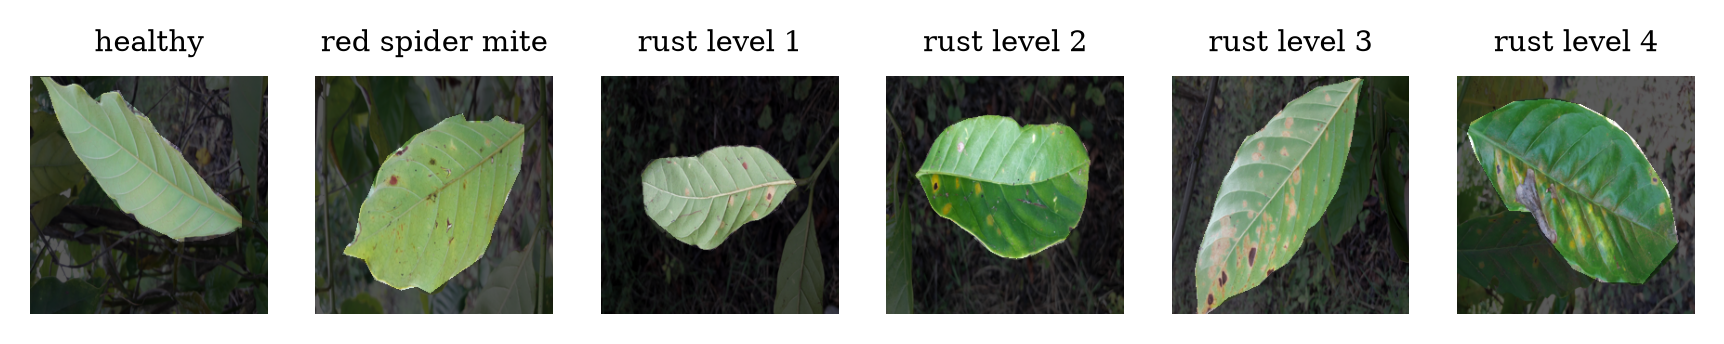

In [6]:
import matplotlib.pyplot as plt
from src.data import load_cache
from src.report import save_fig, setup_style

c = load_cache(DATA_ROOT)
names = list(c["names"])
setup_style()
examples = meta.sort_values("image").groupby("label").head(1).set_index("label").loc[CLASSES].image.tolist()
fig, axes = plt.subplots(1, len(examples), figsize=(7.16, 1.4))
for ax, img, cls in zip(axes, examples, CLASSES):
    i = names.index(img)
    shown = c["images"][i].astype(float)
    shown[c["masks"][i] == 0] *= 0.35
    ax.imshow(shown.astype("uint8")); ax.set_title(cls.replace("_", " "), fontsize=7); ax.axis("off")
save_fig(fig, REPO / "figures", "ejemplos_mascaras")
from IPython.display import Image as IPImage
display(IPImage(filename=str(REPO / "figures" / "ejemplos_mascaras.png"), width=700))

## Partición por planta (versionada)

In [7]:
from src.split import check_split, make_split, summary_table

check_split(split_df)  # ninguna planta en dos conjuntos, subconjuntos anidados, todas las clases
print("Verificación OK")
display(summary_table(split_df))
again = make_split(meta)  # mismo algoritmo y semilla 42: debe reproducir el CSV versionado
same = (again.set_index("image").split == split_df.set_index("image").split).all()
print("¿El algoritmo reproduce split.csv?", same)

Verificación OK


,set,plants,images,healthy,red_spider_mite,rust_level_1,rust_level_2,rust_level_3,rust_level_4
0,train,273,1092,555,120,238,115,43,21
1,val,58,232,113,22,58,24,10,5
2,test,59,236,123,25,48,27,9,4
3,train_f50,136,544,276,63,118,55,21,11
4,train_f25,68,272,136,33,59,28,11,5


Partición: desviación máxima de proporción por clase = 0.0186


Subconjuntos E3: desviación máxima de proporción por clase = 0.0250
¿El algoritmo reproduce split.csv? True
